In [1]:
import glob
from datetime import datetime, timedelta, timezone
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import genextreme as gev
import cmdline_provenance as cmdprov

from unseen import fileio
from unseen import array_handling
from unseen import process_utils
from unseen import eva
from unseen import stability
from unseen import independence
from unseen import bias_correction
from unseen import time_utils
from unseen import general_utils
#from unseen import moments
from unseen import similarity
from unseen import spatial_selection

In [2]:
model = 'IPSL-CM6A-LR'
var = 'pr'
levels_dict = {}
levels_dict[var] = np.arange(0, 101, 10)
levels_dict['psl'] = np.arange(900, 1100, 3)
levels_dict['zg500'] = np.arange(5000, 6300, 50)
var_cmap = 'YlGnBu'
metric = 'Rx5day'
metric_long = 'Annual maximum 5-day rainfall total'
units = 'mm'
units_dict = {}
units_dict[var] = units
units_dict['psl'] = 'hPa'
units_dict['zg500'] = 'm'
baseline_period = ['1970-01-01', '2017-12-30']  
correction_method = 'multiplicative'

region_name = 'CentralPakistan'
region_lat0 = -10 
region_lat1 = 60
region_lon0 = 40
region_lon1 = 160

map_proj = ccrs.PlateCarree(central_longitude=180)

box_name = 'Central Pakistan'
box_lat0 = 24
box_lat1 = 33
box_lon0 = 65
box_lon1 = 71

dist_min = 0
dist_max = 120

outdir = '/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data'
obs_list = ['era5', 'mswep', 'cpc']
obs_file = {}
obs_file['era5'] = f'{outdir}/rx5day_ERA5_1940-2025_annual_central-pakistan.nc'
obs_file['mswep'] = f'{outdir}/rx5day_MSWEP_1979-2025_annual_central-pakistan.nc'
obs_file['cpc'] = f'{outdir}/rx5day_CPC_1979-2025_annual_central-pakistan.nc'
model_file = f'{outdir}/rx5day_IPSL-CM6A-LR-dcppA-hindcast_196101-201701_annual_central-pakistan.nc'

obs_name = {
    'era5': 'ERA5',
    'cpc': 'Climate Prediction Center (CPC) Global Unified Gauge-Based Analysis of Daily Precipitation',
    'mswep': 'Multi-Source Weighted-Ensemble Precipitation (MSWEP)',
}

obs_source = {
    'era5': 'https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview',
    'cpc': 'https://psl.noaa.gov/data/gridded/data.cpc.globalprecip.html',
    'mswep': 'https://www.gloh2o.org/',
}

annual_infile_dict = {}
annual_infile_dict['psl'] = f'{outdir}/psl-jul-aug_IPSL-CM6A-LR-dcppA-hindcast_196101-201701_annual_asia.nc'
annual_infile_dict['zg500'] = f'{outdir}/zg500-jul-aug_IPSL-CM6A-LR-dcppA-hindcast_196101-201701_annual_asia.nc'

code_url = 'https://github.com/ClimateVHT/unseen-projects/tree/master/project-wcrp-rx5day'
history_log = cmdprov.new_log(code_url=code_url)

global_attrs = {
    'institution': 'CSIRO',
    'method': 'UNSEEN',
    'event': 'Pakistan Floods',
    'project': 'WCRP Common Event Attribution and Assessment',
    'contact': 'damien.irving@csiro.au',
    'source': model,
    'experiment': 'dcppA-hindcast',
    'references': 'Decadal Climate Prediction Project (DCPP): https://doi.org/10.5194/gmd-9-3751-2016. UNSEEN methodology: https://doi.org/10.1002/met.70118',
    'creation_date': datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
    'history': history_log,
}
    

In [3]:
def get_encoding(ds, skip_vars=[]):
    """Output file encoding."""

    encoding = {}
    ds_vars = list(ds.coords) + list(ds.keys())
    for ds_var in ds_vars:
        if ds_var not in skip_vars:
            encoding[ds_var] = {'_FillValue': None}

    return encoding

In [4]:
def likelihood(data, event):
    """Calculate event likelihood"""

    shape, loc, scale = eva.fit_gev(data)
    probability = gev.sf(event, shape, loc=loc, scale=scale)
    return_period = 1. / probability
    percentile = (1 - probability) * 100
    print(f'{return_period:.0f} year return period')
    print(f'{percentile:.2f}% percentile')

    return shape, loc, scale

## Read observations

In [5]:
obs_ds = {}
obs_2022_event = {}
for obs in obs_list:
    obs_ds[obs] = fileio.open_dataset(obs_file[obs])
    obs_ds[obs] = obs_ds[obs].dropna("time")
    obs_2022_event[obs] = obs_ds[obs][var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]
    print(f'{obs}: {obs_2022_event[obs]:.1f} {units}')

era5: 83.0 mm
mswep: 86.1 mm
cpc: 118.3 mm


## Read (and test) model data

In [6]:
model_ds = fileio.open_dataset(model_file)

In [7]:
model_ds = model_ds.compute()
model_ds

<xarray.Dataset> Size: 279kB
Dimensions:     (init_date: 57, ensemble: 10, lead_time: 10)
Coordinates:
    event_time  (init_date, ensemble, lead_time) <U10 228kB '1961-07-30' ... ...
  * ensemble    (ensemble) int64 80B 0 1 2 3 4 5 6 7 8 9
  * lead_time   (lead_time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * init_date   (init_date) object 456B 1961-01-01 00:00:00 ... 2017-01-01 00...
    time        (lead_time, init_date) object 5kB 1961-01-01 00:00:00 ... 202...
Data variables:
    pr          (init_date, ensemble, lead_time) float64 46kB 24.49 ... 27.9
Attributes: (12/52)
    name:                   /ccc/work/cont003/gencmip6/flavoni/IGCM_OUT/IPSLC...
    Conventions:            CF-1.7 CMIP-6.2
    creation_date:          2019-03-29T14:40:36Z
    description:            A1 (and A2.1, A3.1, and A3.2) Decadal hindcasts b...
    title:                  IPSL-CM6A-LR model output prepared for CMIP6 / DC...
    activity_id:            DCPP
    ...                     ...
    branch_time_in_parent:  22280.0
    sub_experiment:         initialized near end of year 1960
    tracking_id:            hdl:21.14100/521eb460-8e4b-44d5-8010-e7b978713519
    further_info_url:       https://furtherinfo.es-doc.org/CMIP6.IPSL.IPSL-CM...
    sub_experiment_id:      s1960
    history:                Thu Oct 15 17:17:59 2026: /g/data/xv83/dbi599/min...

#### Stability and stationarity

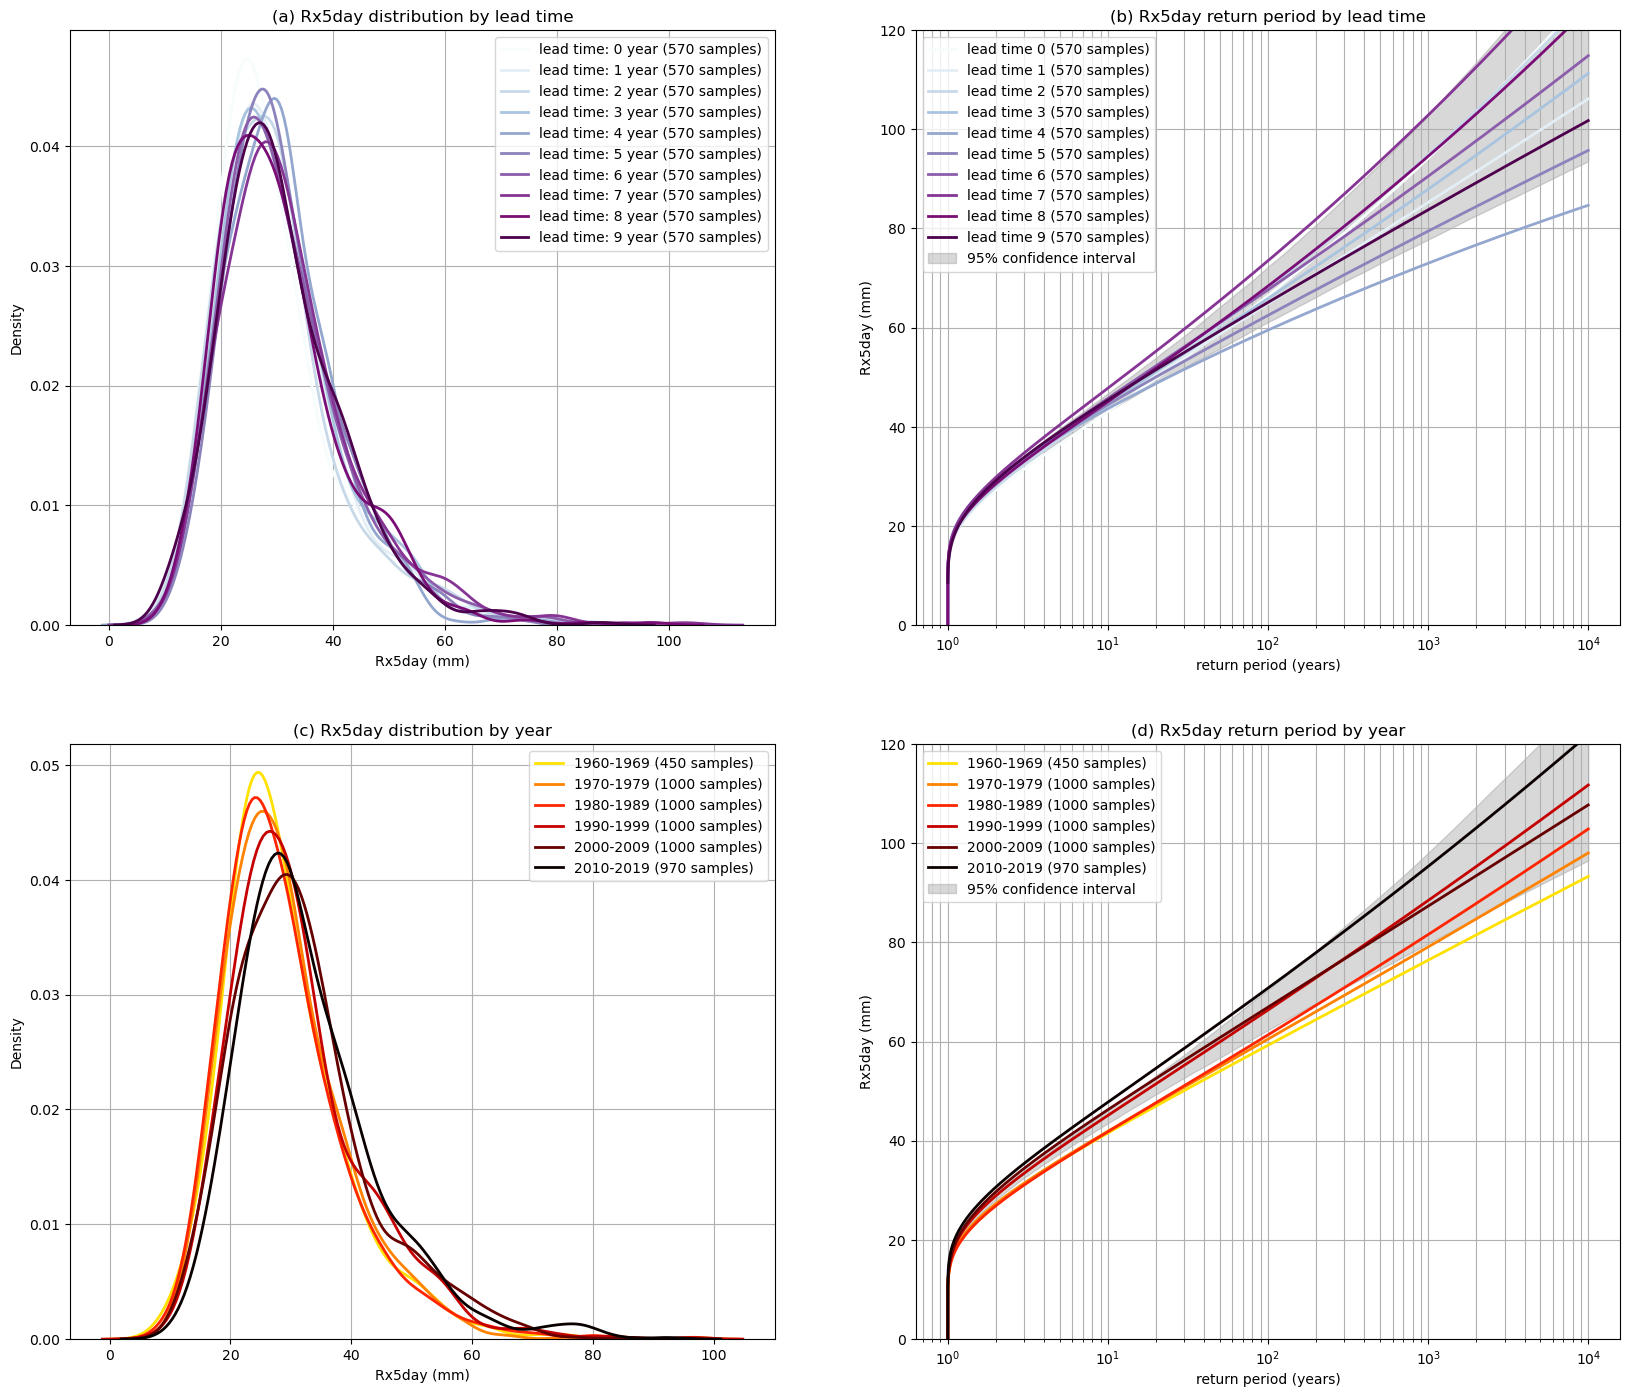

In [8]:
stability.create_plot(
    model_ds[var],
    metric,
    [1960, 1970, 1980, 1990, 2000, 2010],
    uncertainty=True,
    return_method='gev',
    units=f'{metric} ({units})',
    ylim=(dist_min, dist_max),
)

#### Independence

In [9]:
independence_ds = independence.run_tests(model_ds[var])

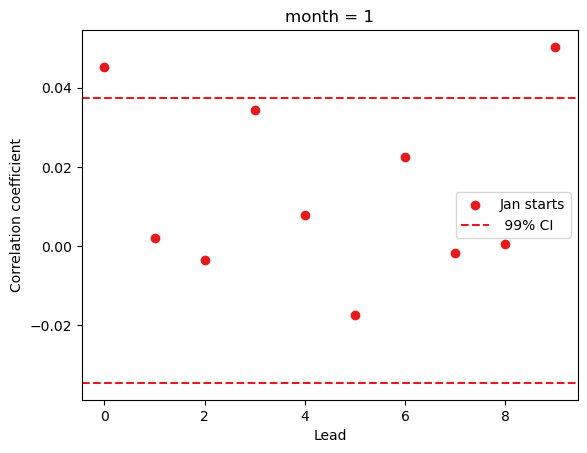

In [10]:
independence.point_plot(
    independence_ds,
    confidence_interval=0.99,
)

In [11]:
min_lead = 1

Drop lead times that aren't independent...

In [12]:
model_da_indep = model_ds[var].where(model_ds['lead_time'] >= min_lead)
model_da_indep = model_da_indep.dropna('lead_time')

In [13]:
model_da_indep_stacked = model_da_indep.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

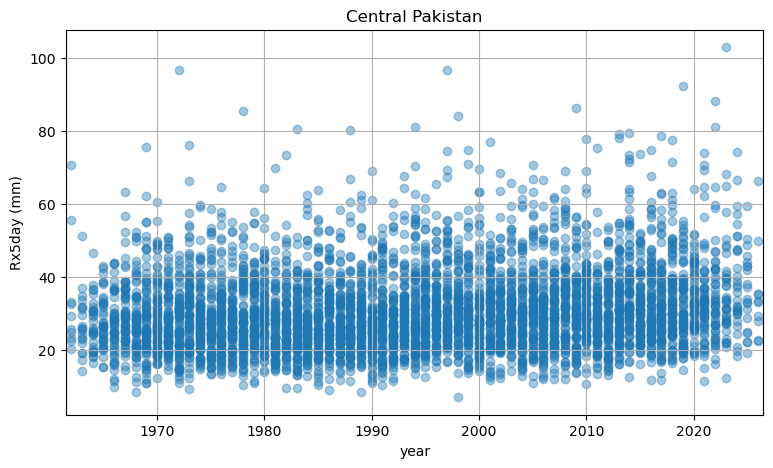

In [14]:
fig, ax = plt.subplots(figsize=[9, 5])
years = model_da_indep_stacked['time'].dt.year.values
unique_years = np.unique(model_da_indep_stacked.time.dt.year.values)

plt.scatter(
    years,
    model_da_indep_stacked.values,
    marker='o',
    color='tab:blue',
    alpha=0.4,
    label='raw data'
)
plt.xlim(unique_years[0] - 0.5, unique_years[-1] + 0.5)
plt.title(box_name)
plt.ylabel(f'{metric} ({units})')
plt.xlabel('year')
#plt.legend()
plt.grid()
plt.show()

#### Bias correction

In [15]:
bias = {}
bias_value = {}
for obs in obs_list:
    bias[obs] = bias_correction.get_bias(
        model_da_indep,
        obs_ds[obs][var],
        correction_method,
        time_rounding='A',
    )
    bias_value[obs] = bias[obs].values[0]
    print(f'{obs}: {bias_value[obs]:.2f}')

era5: 0.82
mswep: 0.78
cpc: 1.10


In [16]:
model_da_bc = {}
model_da_bc_stacked = {}
for obs in obs_list:
    model_da_bc[obs] = bias_correction.remove_bias(model_da_indep, bias[obs], correction_method)
    model_da_bc[obs] = model_da_bc[obs].compute()
    model_da_bc_stacked[obs] = model_da_bc[obs].stack({'sample': ['ensemble', 'init_date', 'lead_time']})

#### Similarity testing

In [17]:
def plot_dist(obs):
    """Plot distribution."""

    fig, ax = plt.subplots(figsize=[8, 5])
    xvals = np.arange(dist_min, dist_max, 0.1)

    title = f'{box_name} - full timeseries'
    model_da_indep.plot.hist(bins=20, density=True, alpha=0.7, facecolor='tab:blue')
    model_raw_shape, model_raw_loc, model_raw_scale = eva.fit_gev(model_da_indep_stacked.values, use_basinhopping=True)
    model_da_bc[obs].plot.hist(bins=50, density=True, alpha=0.7, facecolor='tab:orange')
    model_bc_shape, model_bc_loc, model_bc_scale = eva.fit_gev(model_da_bc_stacked[obs].values, use_basinhopping=True)
    obs_ds[obs][var].plot.hist(ax=ax, bins=50, density=True, facecolor='tab:gray', alpha=0.7)
    obs_shape, obs_loc, obs_scale = eva.fit_gev(obs_ds[obs][var].values, use_basinhopping=True)
    
    model_raw_pdf = gev.pdf(xvals, model_raw_shape, model_raw_loc, model_raw_scale)
    plt.plot(xvals, model_raw_pdf, color='tab:blue', linewidth=4.0, label='model')
    
    model_bc_pdf = gev.pdf(xvals, model_bc_shape, model_bc_loc, model_bc_scale)
    plt.plot(xvals, model_bc_pdf, color='tab:orange', linewidth=4.0, label='model (corrected)')
    
    obs_pdf = gev.pdf(xvals, obs_shape, obs_loc, obs_scale)
    plt.plot(xvals, obs_pdf, color='tab:gray', linewidth=4.0, label=obs.upper())
    
    plt.xlabel(f'{metric} ({units})')
    plt.ylabel('probability')
    plt.title(title)
    plt.xlim(dist_min, dist_max)
    plt.legend()
    plt.grid()
    plt.show()

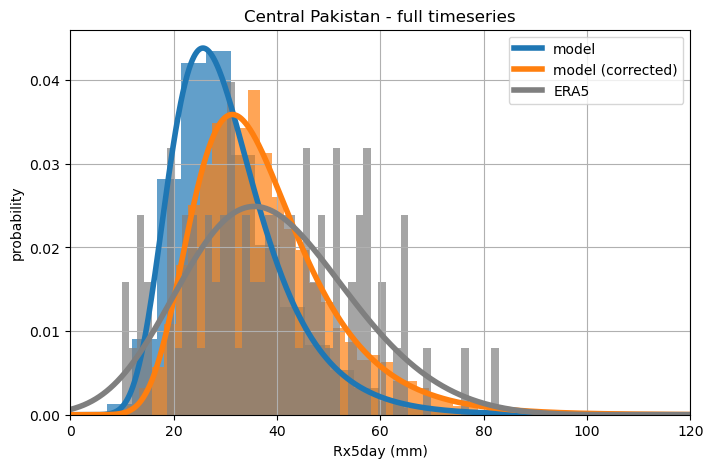

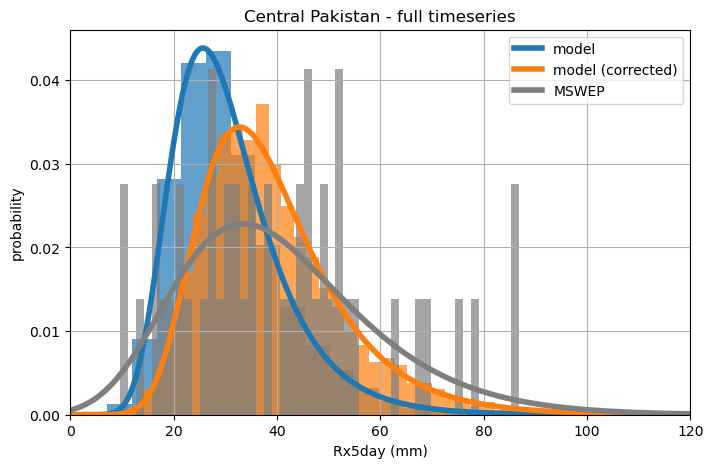

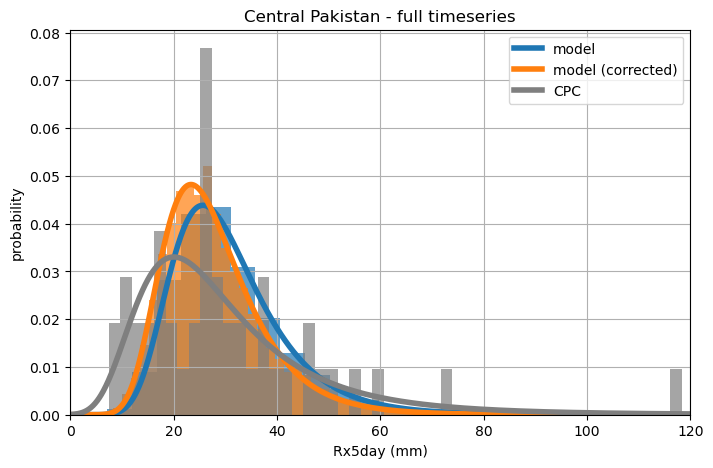

In [18]:
for obs in obs_list:
    plot_dist(obs)

In [19]:
similarity_ds_indep = {}
similarity_ds_bc = {}
ks_indep_pass = {}
ks_bc_pass = {}
for obs in obs_list:
    similarity_ds_indep[obs] = similarity.similarity_tests(model_da_indep, obs_ds[obs][var])
    ks_indep_pass[obs] = 'Pass' if similarity_ds_indep[obs]['ks_pval'].values > 0.05 else 'Fail'
    print(f'Raw model data vs {obs.upper()}:')
    print('  KS score:', similarity_ds_indep[obs]['ks_statistic'].values)
    print('  KS p-value:', f'{similarity_ds_indep[obs]['ks_pval'].values} ({ks_indep_pass[obs]})')
    print('  AD score:', similarity_ds_indep[obs]['ad_statistic'].values)
    print('  AD p-value:', similarity_ds_indep[obs]['ad_pval'].values)
    
    similarity_ds_bc[obs] = similarity.similarity_tests(model_da_bc[obs], obs_ds[obs][var])
    ks_bc_pass[obs] = 'Pass' if similarity_ds_bc[obs]['ks_pval'].values > 0.05 else 'Fail'
    print(f'Bias corrected model data vs {obs.upper()}:')
    print('  KS score:', similarity_ds_bc[obs]['ks_statistic'].values)
    print('  KS p-value:', f'{similarity_ds_bc[obs]['ks_pval'].values} ({ks_bc_pass[obs]})')
    print('  AD score:', similarity_ds_bc[obs]['ad_statistic'].values)
    print('  AD p-value:', similarity_ds_bc[obs]['ad_pval'].values)

Raw model data vs ERA5:
  KS score: 0.3157804
  KS p-value: 5.387600410244886e-08 (Fail)
  AD score: 25.448132
  AD p-value: 0.001
Bias corrected model data vs ERA5:
  KS score: 0.13931729
  KS p-value: 0.06785862147808075 (Pass)
  AD score: 4.8078194
  AD p-value: 0.004068462
Raw model data vs MSWEP:
  KS score: 0.35018042
  KS p-value: 1.3076116374577396e-05 (Fail)
  AD score: 15.635281
  AD p-value: 0.001
Bias corrected model data vs MSWEP:
  KS score: 0.16555099
  KS p-value: 0.13872632384300232 (Pass)
  AD score: 3.228308
  AD p-value: 0.015875533
Raw model data vs CPC:
  KS score: 0.2064203
  KS p-value: 0.03222990781068802 (Fail)
  AD score: 5.706555
  AD p-value: 0.0019524825
Bias corrected model data vs CPC:
  KS score: 0.16450998
  KS p-value: 0.14336346089839935 (Pass)
  AD score: 3.754109
  AD p-value: 0.009988801


p > 0.05 means that the null hypothesis (that the two samples are from the same population) cannot be rejected.

#### Process assessment

In [20]:
def ensemble_to_run(model_name, ensnum):
    """Map ensemble number to DCPP model run"""

    norcpm_dict = {
        1: 'r1i1p1f1',
        2: 'r1i2p1f1',
        3: 'r2i1p1f1',
        4: 'r2i2p1f1',
        5: 'r3i1p1f1',
        6: 'r3i2p1f1',
        7: 'r4i1p1f1',
        8: 'r4i2p1f1',
        9: 'r5i1p1f1',
        10: 'r5i2p1f1',
        11: 'r6i1p1f1',
        12: 'r6i2p1f1',
        13: 'r7i1p1f1',
        14: 'r7i2p1f1',
        15: 'r8i1p1f1',
        16: 'r8i2p1f1',
        17: 'r9i1p1f1',
        18: 'r9i2p1f1',
        19: 'r10i1p1f1',
        20: 'r10i2p1f1',
    }

    ecearth_dict = {
        1: 'r1i1p1f1',
        2: 'r2i1p1f1',
        3: 'r3i1p1f1',
        4: 'r4i1p1f1',
        5: 'r5i1p1f1',
        6: 'r6i1p1f1',
        7: 'r6i2p1f1',
        8: 'r7i1p1f1',
        9: 'r7i2p1f1',
        10: 'r8i1p1f1',
        11: 'r8i2p1f1',
        12: 'r9i1p1f1',
        13: 'r9i2p1f1',
        14: 'r10i1p1f1',
        15: 'r10i2p1f1',
    }

    if model_name == 'EC-Earth3':
        run = ecearth_dict[ensnum]
    elif model_name == 'NorCPM1':
        run = norcpm_dict[ensnum]
    else:
        ensemble_to_run = { 
            'BCC-CSM2-MR': f'r{ensnum}i1p1f1',
            'CanESM5': f'r{ensnum}i1p2f1',
            'CMCC-CM2-SR5': f'r{ensnum}i1p1f1',
            'HadGEM3-GC31-MM': f'r{ensnum}i1p1f2',
            'IPSL-CM6A-LR': f'r{ensnum}i1p1f1',
            'MIROC6': f'r{ensnum}i1p1f1',
            'MPI-ESM1-2-HR': f'r{ensnum}i1p1f1',
            'MRI-ESM2-0': f'r{ensnum}i1p1f1',
        }
        run = ensemble_to_run[model_name]

    return run
    

def find_dcpp_data(event_df_row, model_name):
    """Find DCPP data for one row of a dataframe of events."""

    init_adjustment = {
        'BCC-CSM2-MR': 0,
        'CanESM5': -1,
        'CMCC-CM2-SR5': -1,
        'EC-Earth3': -1,
        'IPSL-CM6A-LR': -1,
        'MIROC6': -1,
        'MPI-ESM1-2-HR': -1,
        'MRI-ESM2-0': -1,
        'NorCPM1': -1,
    }

    assert model_name in init_adjustment
    
    init_date = int(event_df_row['init_date'].strftime('%Y')) + init_adjustment[model_name]
    ensemble = int(event_df_row['ensemble']) + 1
    run = ensemble_to_run(model_name, ensemble)
    event_date = event_df_row['event_time']
    event_value = round(float(event_df_row[var]), 1)
    event_summary = f'{metric} of {event_value} on {event_date}: initialisation year {init_date}, ensemble member {run}'
    print(event_summary)
    var_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/{var}/*/*/*.nc')
    assert var_files
    psl_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/psl/*/*/*.nc')
    zg500_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/AERday/zg500/*/*/*.nc')

    return var_files, psl_files, zg500_files, event_date, event_value, event_summary

In [21]:
def event_check(da, event_value):
    """Check the event value"""

    da_box = da.sel(lat=slice(box_lat0, box_lat1), lon=slice(box_lon0, box_lon1))
    da_box_mean = spatial_selection.aggregate(da_box, 'weighted_mean')
    
    np.testing.assert_approx_equal(float(da_box_mean), event_value, significant=1)
    # np.testing.assert_approx_equal(float(da_box_mean) - bias_value, event_value, significant=1)
    

def get_start_date(event_date):
    """Get start date."""

    event_datetime = datetime.strptime(event_date, "%Y-%m-%d")
    start_datetime = event_datetime - timedelta(days=4)
    start_date = start_datetime.strftime("%Y-%m-%d")

    return start_date


def get_event_data(event_df_row, model_name):
    """Plot an event"""

    infiles_var, infiles_psl, infiles_zg500, event_date, event_value, event_summary = find_dcpp_data(event_df_row, model_name)
    dcpp_config = '/home/599/dbi599/unseen-projects/dataset_config/dataset_dcpp.yml'

    start_date = get_start_date(event_date)

    ds_var = fileio.open_dataset(infiles_var, metadata_file=dcpp_config)
    ds_var = ds_var.sel(
        time=slice(start_date, event_date),
        lat=slice(region_lat0 - 5, region_lat1 + 5),
        lon=slice(region_lon0 - 5, region_lon1 + 5),
    )
    da_var = general_utils.convert_units(ds_var[var], units)
    da_var = da_var.sum('time', keep_attrs=True)
#    da_var.attrs['units'] = units
    event_check(da_var, event_value)

    if infiles_psl:
        ds_psl = fileio.open_dataset(infiles_psl, metadata_file=dcpp_config)
        ds_psl = ds_psl.sel(
            time=slice(start_date, event_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_psl = general_utils.convert_units(ds_psl['psl'], 'hPa')
        da_psl = da_psl.mean('time', keep_attrs=True)
    else:
        da_psl = None
    
    if infiles_zg500:
        ds_zg500 = fileio.open_dataset(infiles_zg500, metadata_file=dcpp_config)
        ds_zg500 = ds_zg500.sel(
            time=slice(start_date, event_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_zg500 = ds_zg500['zg500']
        da_zg500 = da_zg500.mean('time', keep_attrs=True)
    else:
        da_zg500 = None

    return da_var, da_psl, da_zg500

In [22]:
def plot_event(da_var, da_contour, contour_var):
    """Plot event."""

    assert contour_var in ['psl', 'zg500']
    
    fig = plt.figure(figsize=[15, 5])
    ax = fig.add_subplot(111, projection=map_proj)
    
    da_var.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=var_cmap,
        levels=levels_dict[var],
        extend='both',
    #    cbar_kwargs={"label": label},
    )
    if type(da_contour) != type(None):
        lines = da_contour.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=levels_dict[contour_var],
            colors=["0.3"]
        )
        ax.clabel(lines, colors=["0.3"], manual=False, inline=True)
    
    ax.plot(
        [box_lon0, box_lon0, box_lon1, box_lon1, box_lon0],
        [box_lat1, box_lat0, box_lat0, box_lat1, box_lat1],
        transform=ccrs.PlateCarree(),
        color='green',
    )   
    ax.coastlines()
    #ax.set_extent([180, 300, 30, 70], crs=ccrs.PlateCarree(central_longitude=0))
    ax.add_feature(cartopy.feature.BORDERS)
    ax.gridlines(linestyle="--", draw_labels=True)
    
    plt.show()

In [23]:
model_da_indep_stacked_df = model_da_indep_stacked.to_dataframe()
nsamples = len(model_da_indep_stacked_df)
model_da_indep_stacked_df.index = range(1, nsamples + 1)
model_da_indep_stacked_df_sorted = model_da_indep_stacked_df.sort_values(by=[var], ascending=False)
model_da_indep_stacked_df_sorted.head(n=10)

,event_time,time,ensemble,init_date,lead_time,pr
5119,2023-08-15,2023-01-01 00:00:00,9,2016-01-01 00:00:00,7,102.816757
2087,1972-12-06,1972-01-01 00:00:00,4,1964-01-01 00:00:00,8,96.677574
4412,1997-11-06,1997-01-01 00:00:00,8,1995-01-01 00:00:00,2,96.504135
4570,2019-10-24,2019-01-01 00:00:00,8,2012-01-01 00:00:00,7,92.321358
2016,2022-08-01,2022-01-01 00:00:00,3,2013-01-01 00:00:00,9,88.005501
921,2009-11-23,2009-01-01 00:00:00,1,2006-01-01 00:00:00,3,86.318893
1115,1978-11-03,1978-01-01 00:00:00,2,1970-01-01 00:00:00,8,85.331940
1856,1998-11-24,1998-01-01 00:00:00,3,1996-01-01 00:00:00,2,84.107521
3832,1994-10-06,1994-01-01 00:00:00,7,1987-01-01 00:00:00,7,81.131218
4092,2022-01-02,2022-01-01 00:00:00,7,2016-01-01 00:00:00,6,80.983162


In [24]:
nsamples = len(model_da_indep_stacked_df)
print(f'Total number of samples: {nsamples}')

Total number of samples: 5130


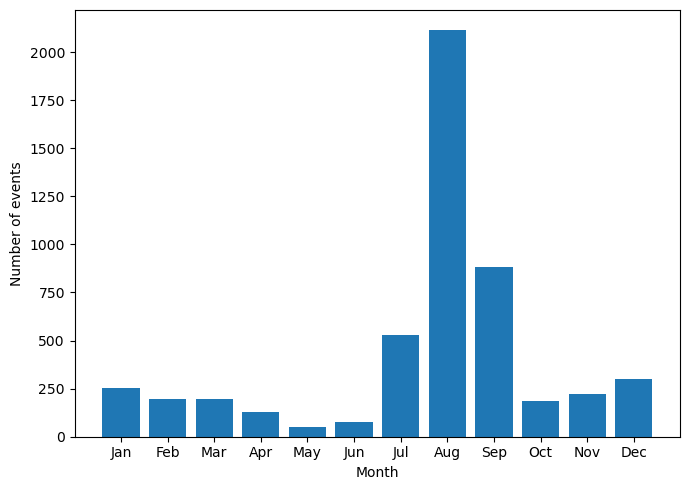

In [25]:
process_utils.plot_event_seasonality(model_da_indep_stacked, core_dim='sample')

Rx5day of 102.8 on 2023-08-15: initialisation year 2015, ensemble member r10i1p1f1


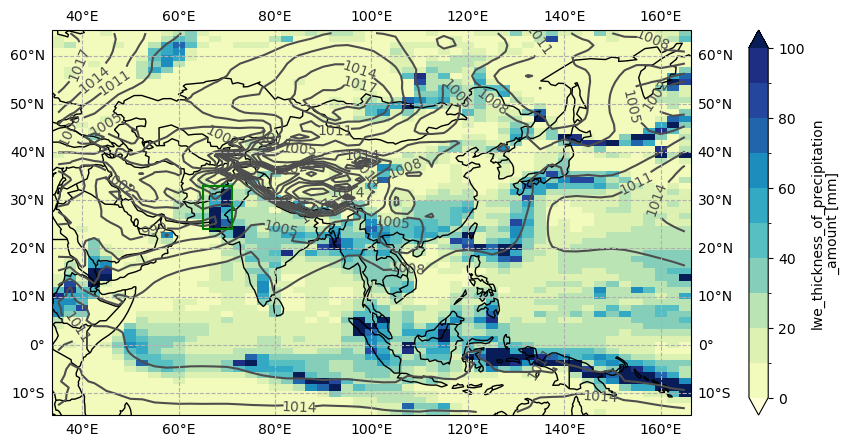

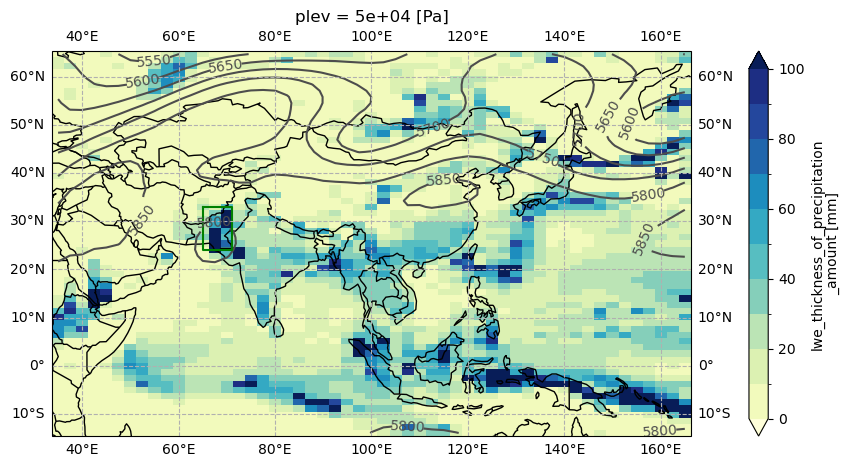

Rx5day of 96.7 on 1972-12-06: initialisation year 1963, ensemble member r5i1p1f1


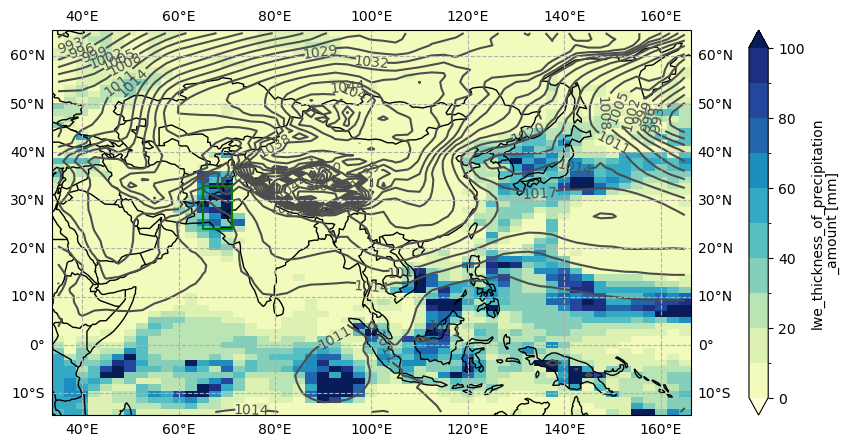

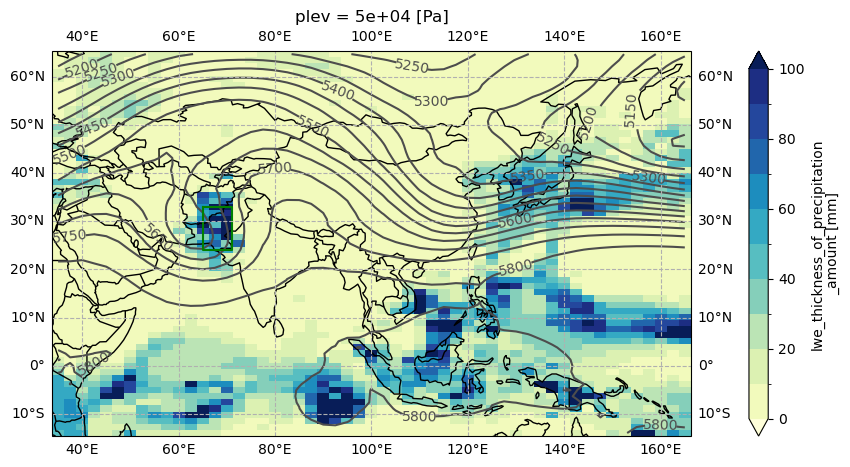

Rx5day of 96.5 on 1997-11-06: initialisation year 1994, ensemble member r9i1p1f1


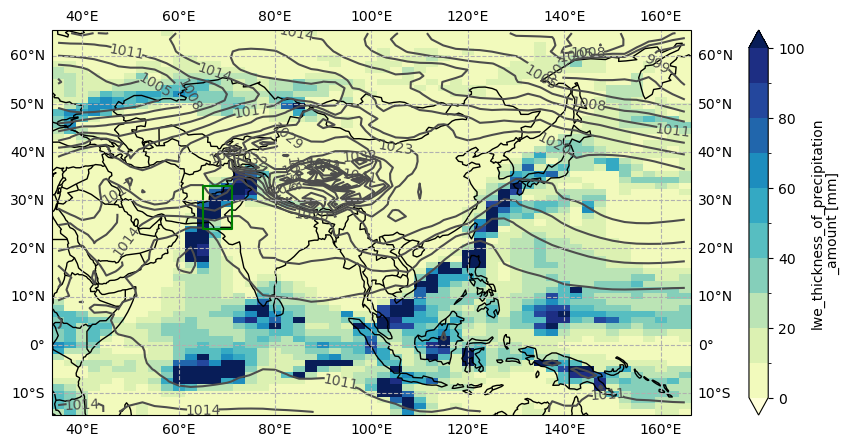

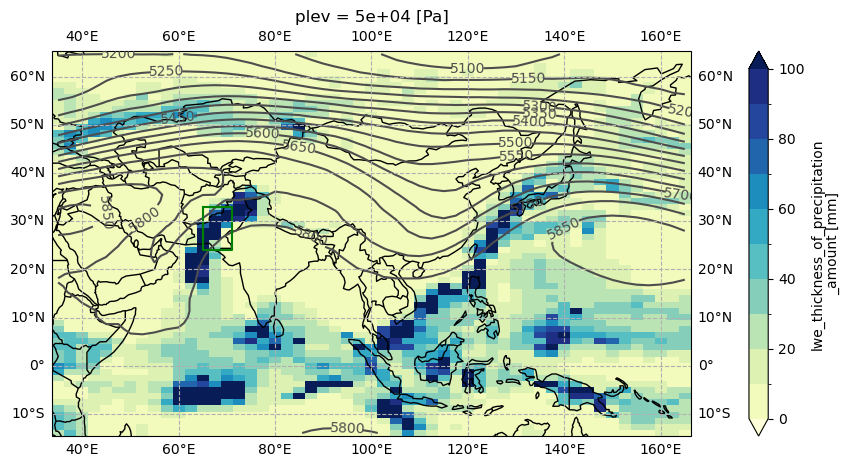

Rx5day of 92.3 on 2019-10-24: initialisation year 2011, ensemble member r9i1p1f1


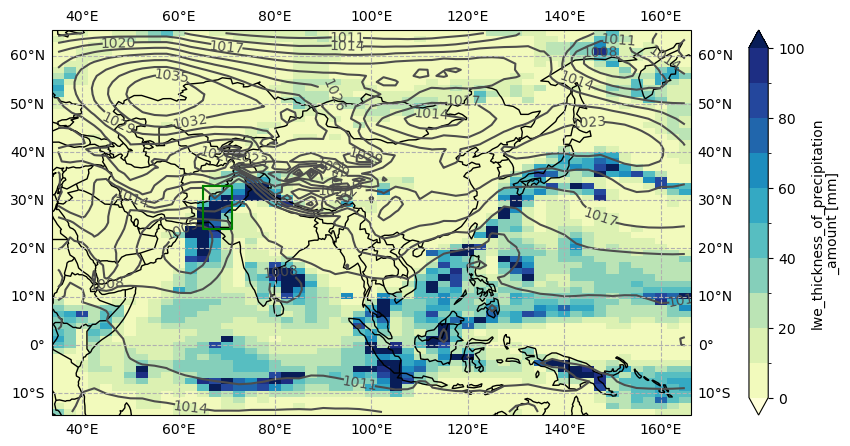

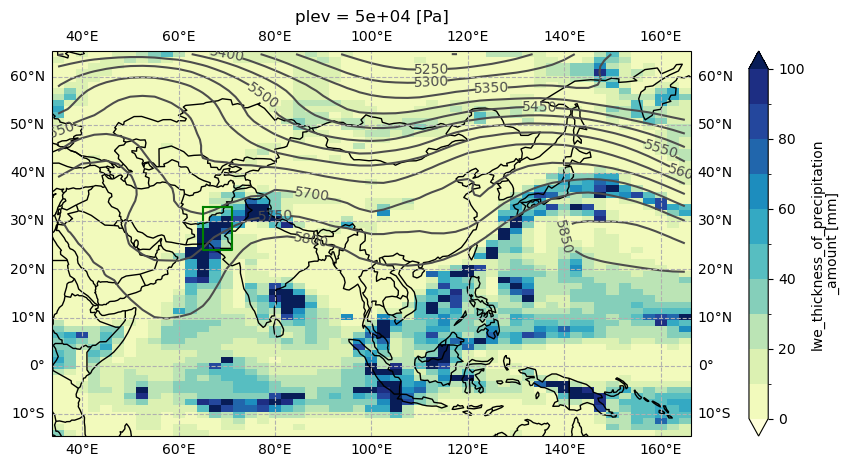

Rx5day of 88.0 on 2022-08-01: initialisation year 2012, ensemble member r4i1p1f1


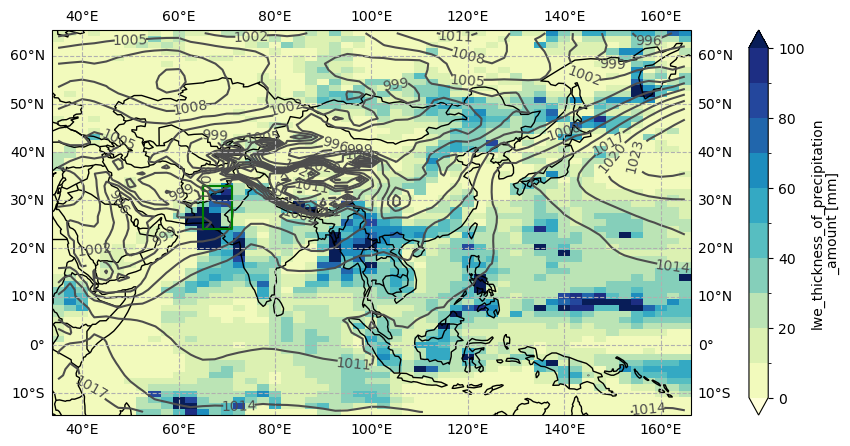

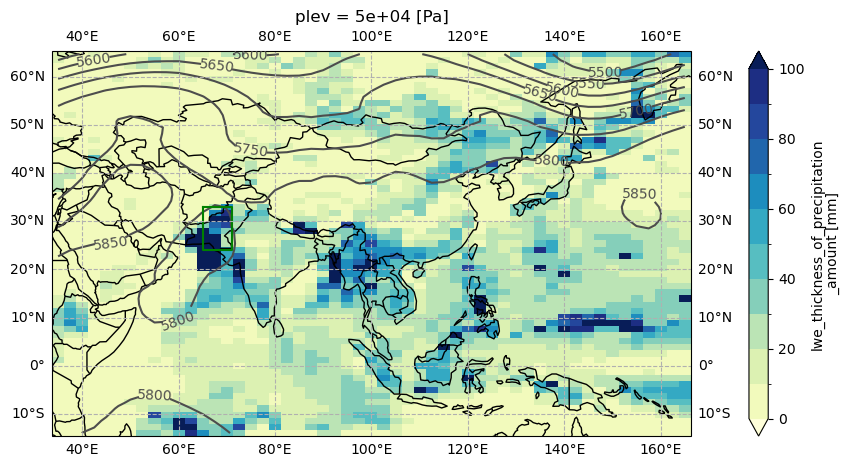

Rx5day of 86.3 on 2009-11-23: initialisation year 2005, ensemble member r2i1p1f1


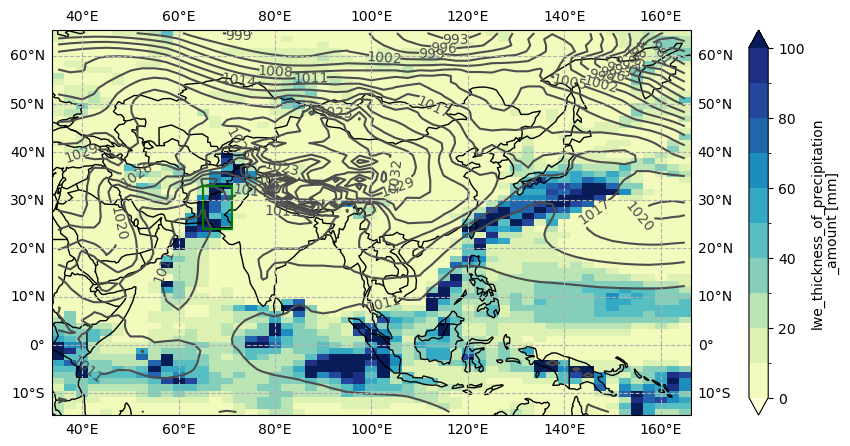

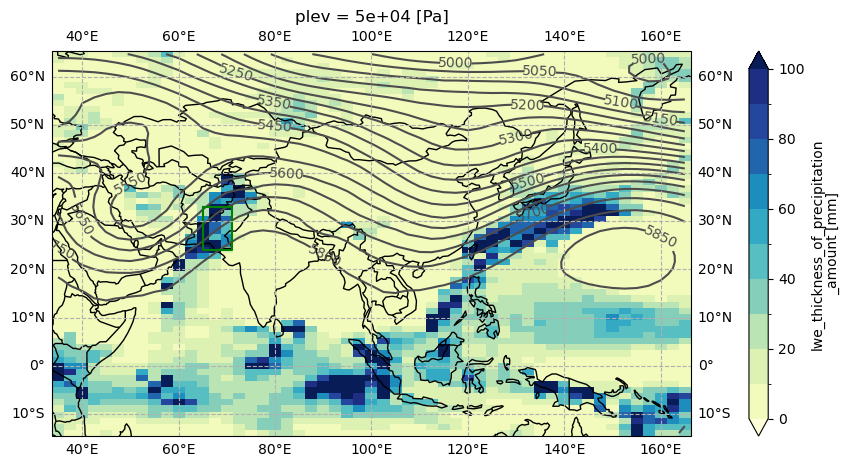

Rx5day of 85.3 on 1978-11-03: initialisation year 1969, ensemble member r3i1p1f1


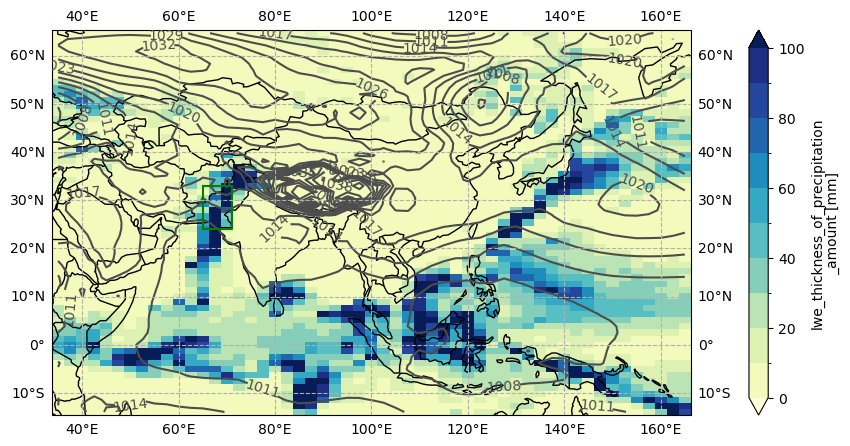

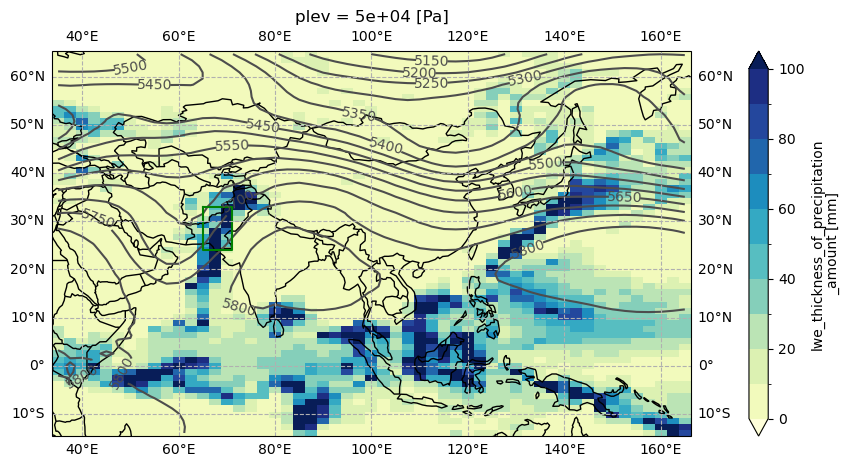

Rx5day of 84.1 on 1998-11-24: initialisation year 1995, ensemble member r4i1p1f1


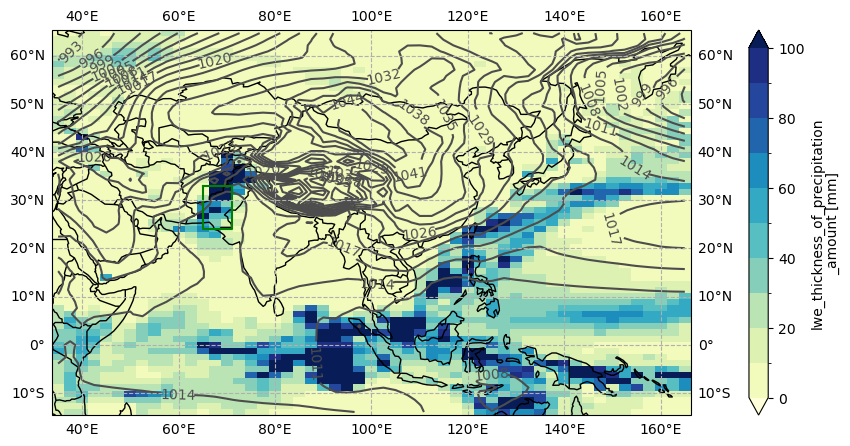

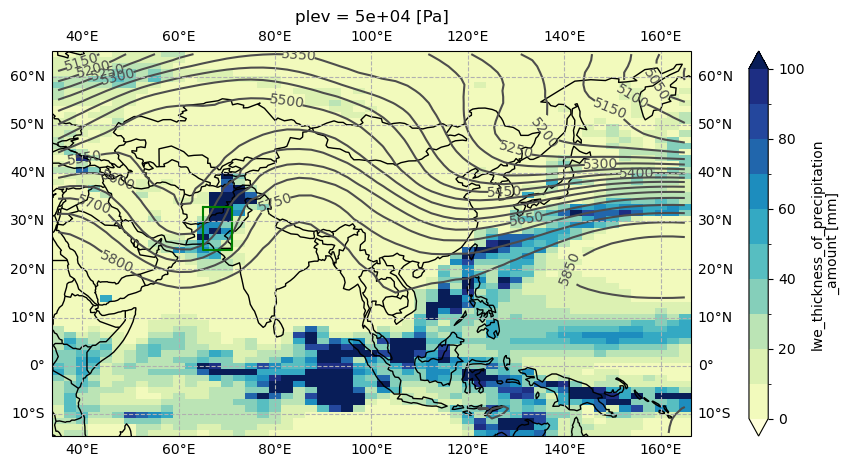

Rx5day of 81.1 on 1994-10-06: initialisation year 1986, ensemble member r8i1p1f1


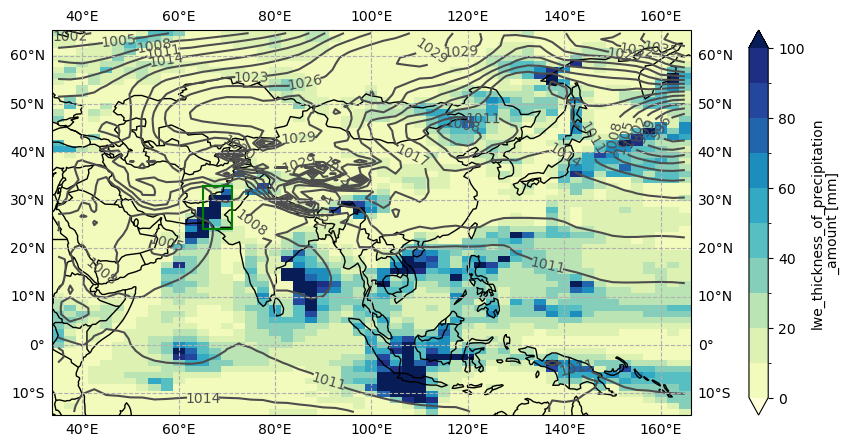

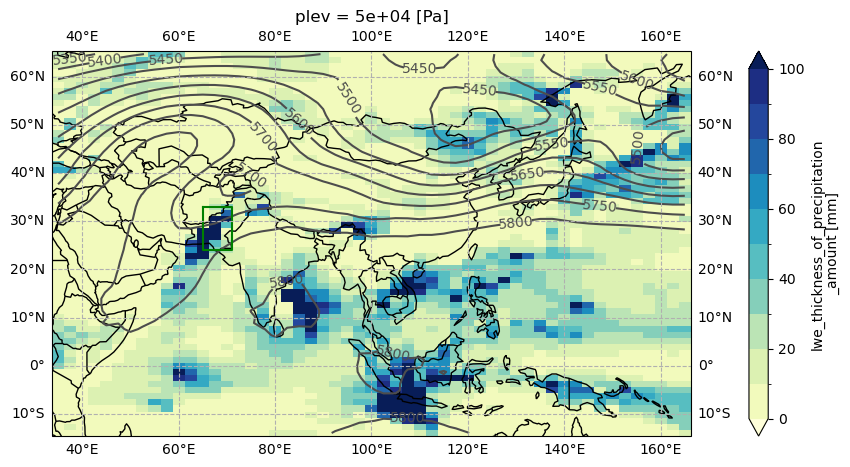

Rx5day of 81.0 on 2022-01-02: initialisation year 2015, ensemble member r8i1p1f1


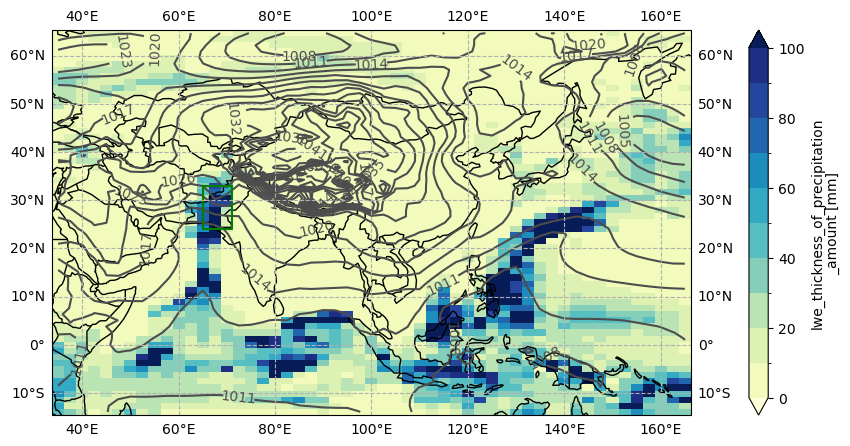

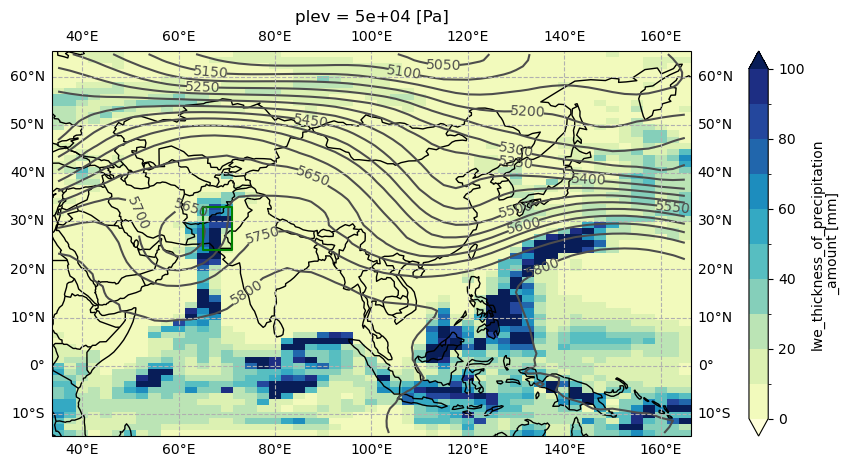

In [26]:
da_var_dict = {}
da_psl_dict = {}
da_zg500_dict = {}
for rank in range(10):
    number = model_da_indep_stacked_df_sorted.iloc[rank].name
    da_var_dict[number], da_psl_dict[number], da_zg500_dict[number] = get_event_data(
        model_da_indep_stacked_df_sorted.iloc[rank], model
    )
    plot_event(da_var_dict[number], da_psl_dict[number], 'psl')
    plot_event(da_var_dict[number], da_zg500_dict[number], 'zg500')

## Results

#### Extreme value analysis

In [27]:
def calc_return_period(model_da_samples_stacked, event):
    """Perform extreme value analysis"""

    daparams = eva.fit_gev(
        model_da_samples_stacked,
        core_dim="sample",
        stationary=True,
        use_basinhopping=True,
    )

    return_period = float(eva.get_return_period(event, daparams).values)

    # parametric uncertainty estimate
    n_bootstraps = 1000
    shape, loc, scale = eva.unpack_gev_params(daparams)
    sample_size = len(model_da_samples_stacked)
    boot_samples = []
    for i in range(n_bootstraps):
        boot_data = gev.rvs(float(shape), loc=float(loc), scale=float(scale), size=sample_size)
        boot_gev_params = eva.fit_gev(boot_data)
        boot_return_period = eva.get_return_period(event, boot_gev_params)
        boot_samples.append(boot_return_period)
    ci05 = np.percentile(boot_samples, 5)
    ci16 = np.percentile(boot_samples, 16)
    ci84 = np.percentile(boot_samples, 84)
    ci95 = np.percentile(boot_samples, 95)

    print(f'The return period of a {event:.2f} {units} event is {return_period:.0f} years.')
    print(f'The 5-95% confidence interval is {ci05:.0f} to {ci95:.0f} years.')
    print(f'The 16-84% confidence interval is {ci16:.0f} to {ci84:.0f} years.')

In [28]:
step_bias = {}
for obs in obs_list:
    if ks_indep_pass[obs] == 'Pass':
        step_bias[obs] = f'No bias correction was applied to the {metric} values.'
        print(f'{obs.upper()}: raw data passes the similarity test')
        calc_return_period(model_da_indep_stacked, obs_2022_event[obs])
    elif ks_bc_pass[obs] == 'Pass':
        step_bias[obs] = f'Applied bias correction to the {metric} values (multiplicative scaling relative to the {obs_name[obs]} observational dataset).'
        print(f'{obs.upper()}: bias correction passes the similarity test')
        calc_return_period(model_da_bc_stacked[obs], obs_2022_event[obs])
    else:
        print(f'{obs.upper()}: data fails similarity test before and after bias correction')

ERA5: bias correction passes the similarity test
The return period of a 82.97 mm event is 122 years.
The 5-95% confidence interval is 103 to 151 years.
The 16-84% confidence interval is 110 to 137 years.
MSWEP: bias correction passes the similarity test
The return period of a 86.14 mm event is 117 years.
The 5-95% confidence interval is 99 to 142 years.
The 16-84% confidence interval is 106 to 131 years.
CPC: bias correction passes the similarity test
The return period of a 118.31 mm event is 72119 years.
The 5-95% confidence interval is 31768 to 213667 years.
The 16-84% confidence interval is 41735 to 139294 years.


## Supporting data

In [29]:
ecmwf_attrs = {}
ecmwf_attrs['pr'] = {
    'name': 'tp',
    'units': 'mm',
    'long_name': 'Total accumulated 5-day precipitation',
}
ecmwf_attrs['psl'] = {
    'name': 'msl',
    'units': 'Pa',
    'long_name': 'Mean sea level pressure',
}
ecmwf_attrs['zg500'] = {
    'name': 'gh500',
    'units': 'm',
    'long_name': 'Geopotential height at 500 hPa',
}

### Tier 2 data

In [30]:
def write_tier2_data(model_da_samples_stacked, obs_dataset, bc=False):
    """Write Tier 2 data file"""

    model_da_samples_stacked_df = model_da_samples_stacked.to_dataframe()
    nsamples = len(model_da_samples_stacked_df)
    model_da_samples_stacked_df.index = range(1, nsamples + 1)
    
    numbers = model_da_samples_stacked_df.index.values
    da1 = xr.DataArray(
        data=np.round(model_da_samples_stacked_df[var].values, 2),
        coords={'number': numbers,},
        name=metric,
        attrs = {
            'long_name': metric_long,
            'units': units,
        }
    )
    da1 = general_utils.convert_units(da1, ecmwf_attrs[var]['units'])

    try:
        del da1.attrs['units_metadata']
    except KeyError:
        pass
    
    event_times = [time_utils.str_to_cftime(t) for t in model_da_samples_stacked_df['event_time'].values]
    da2 = xr.DataArray(
        data=event_times,
        coords={'number': numbers,},
        name='event_date',
        attrs = {
            'long_name': 'Event date (last day of 5-day event)',
        }
    )

    output_ds = xr.merge([da1, da2])
    output_ds.attrs = global_attrs
    output_ds.attrs['data_tier'] = 'tier2'
    step_download = 'Downloaded daily precipitation data (pr).'
    step_spatial_selection = 'Selected the central Pakistan domain (24-33N, 65-71E).'
    step_spatial_aggregation = 'Computed the cosine-latitude-weighted spatial mean.'
    step_temporal_aggregation = 'Computed the 5-day running sum. Resampled to annual maxima.'
    step_independence = f'Dropped lead times that are not independent (< {min_lead} years).'
    output_ds.attrs['processing'] = f'{step_download} {step_spatial_selection} {step_spatial_aggregation} {step_temporal_aggregation} {step_independence} {step_bias[obs_dataset]}'
    output_ds['number'].attrs['long_name'] = 'Sample number'

    if bc:
        output_ds.attrs['references'] = global_attrs['references'] + f'. {obs_dataset.upper()} dataset: {obs_source[obs_dataset]}' 
    fname = f'{outdir}/CSIRO_UNSEEN_tier2_{model}-{obs_dataset.upper()}.nc'
    encoding = get_encoding(output_ds)
    encoding['event_date']['units'] = 'days since 1960-01-01'
    output_ds.to_netcdf(fname, encoding=encoding)
    print(fname)

In [31]:
for obs in obs_list:
    if ks_indep_pass[obs] == 'Pass':
        write_tier2_data(model_da_indep_stacked, obs, bc=False)
    elif ks_bc_pass[obs] == 'Pass':
        write_tier2_data(model_da_bc_stacked[obs], obs, bc=True)

/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data/CSIRO_UNSEEN_tier2_IPSL-CM6A-LR-ERA5.nc
/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data/CSIRO_UNSEEN_tier2_IPSL-CM6A-LR-MSWEP.nc
/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data/CSIRO_UNSEEN_tier2_IPSL-CM6A-LR-CPC.nc


### Tier 3 data

In [32]:
similarity_results = list(ks_indep_pass.values()) + list(ks_bc_pass.values())

#### 5-day means

In [33]:
def ceaa_format(da, variable, number=None):
    """Modify an array so if conforms with the requested CEAA format"""

    try:
        da = da.drop_vars('height')
    except ValueError:
        pass

    try:
        da = da.drop_vars('plev')
    except ValueError:
        pass

    da = general_utils.convert_units(da, ecmwf_attrs[variable]['units'])

    da = da.rename({'lat': 'latitude', 'lon': 'longitude'})
    da.name = ecmwf_attrs[variable]['name']
    da.attrs = {}
    da.attrs['long_name'] = ecmwf_attrs[variable]['long_name']
    da.attrs['units'] = ecmwf_attrs[variable]['units']

    if number:
        da['number'] = number
        da['number'].attrs['long_name'] = 'Sample number'

    return da

In [34]:
step_download_spatial_select = 'Downloaded daily mean sea level pressure (psl) and 500hPa geopotential height (zg500) data over the 10S-60N, 40-160E domain.'

if 'Pass' in similarity_results:
    da_psl_list = []
    da_zg500_list = []
    skip_vars = []
    for number, da_var in da_var_dict.items():
        da_var_ceaa = ceaa_format(da_var, var, number=number)
        
        da_psl = da_psl_dict[number]
        if type(da_psl) == type(None):
            print(f'missing psl data for sample number {number}') 
            da_psl_ceaa = da_var_ceaa * np.nan
            da_psl_ceaa.name = ecmwf_attrs['psl']['name']
            da_psl_ceaa.attrs['long_name'] = ecmwf_attrs['psl']['long_name']
            da_psl_ceaa.attrs['units'] = ecmwf_attrs['psl']['units']
            skip_vars.append('msl')
        else:
            da_psl_ceaa = ceaa_format(da_psl, 'psl', number=number)
        da_psl_list.append(da_psl_ceaa)
    
        da_zg500 = da_zg500_dict[number]
        if type(da_zg500) == type(None):
            print(f'missing zg500 data for sample number {number}') 
            da_zg500_ceaa = da_var_ceaa * np.nan
            da_zg500_ceaa.name = ecmwf_attrs['zg500']['name']
            da_zg500_ceaa.attrs['long_name'] = ecmwf_attrs['zg500']['long_name']
            da_zg500_ceaa.attrs['units'] = ecmwf_attrs['zg500']['units']
            skip_vars.append('gh500')
        else:
            da_zg500_ceaa = ceaa_format(da_zg500, 'zg500', number=number)
        da_zg500_list.append(da_zg500_ceaa)
    
    ds_psl = xr.concat(da_psl_list, dim='number')
    ds_zg500 = xr.concat(da_zg500_list, dim='number')
    skip_vars = list(set(skip_vars))
    
    ds = xr.merge([ds_psl, ds_zg500])
    ds.attrs = global_attrs
    ds.attrs['data_tier'] = 'tier3'
    step_tstep_select = f'Selected the five-day sequences associated with the top ten most extreme {metric} events. Calculated the 5-day mean psl and zg500 for each event.'
    ds.attrs['processing'] = f'{step_download_spatial_select} {step_tstep_select}'
    encoding = get_encoding(ds, skip_vars=skip_vars)
    outfname = f'{outdir}/CSIRO_UNSEEN_tier3_{model}_5day.nc'
    ds.to_netcdf(outfname, encoding=encoding)
    print(outfname)

/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data/CSIRO_UNSEEN_tier3_IPSL-CM6A-LR_5day.nc


#### Climatologies

They ask for the July-August climatology for the 1991-2020 period.

In [35]:
ds_annual_dict = {}
ds_annual_dict['psl'] = fileio.open_dataset(annual_infile_dict['psl'])
ds_annual_dict['zg500'] = fileio.open_dataset(annual_infile_dict['zg500'])

In [36]:
def calc_clim(ds, clim_var):
    """Calculate climatology"""

    ds = ds.compute()
    ds[var] = general_utils.convert_units(ds[clim_var], units_dict[clim_var])
    ds = array_handling.reindex_forecast(ds)
    da_baseline = ds[clim_var].sel(time=slice('1991-01-01', '2020-12-31'))
    da_clim = da_baseline.mean(dim=['time', 'init_date', 'ensemble'])
    da_clim.attrs['units'] = units_dict[clim_var]

    return da_clim

In [37]:
clim_dict = {}
clim_dict['psl'] = calc_clim(ds_annual_dict['psl'], 'psl')
clim_dict['zg500'] = calc_clim(ds_annual_dict['zg500'], 'zg500')

In [38]:
def plot_climatology(contour_var):
    """Plot the climatology"""

    fig = plt.figure(figsize=[15, 5])
    ax = fig.add_subplot(111, projection=map_proj)

    lines = clim_dict[contour_var].plot.contour(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=levels_dict[contour_var],
        colors=["0.3"]
    )
    ax.clabel(lines, colors=["0.3"], manual=False, inline=True)
    
    ax.coastlines()
    ax.add_feature(cartopy.feature.BORDERS)
    ax.gridlines(linestyle="--", draw_labels=True)
    
    plt.title('1991-2020 climatology (July-August)')
    plt.show()

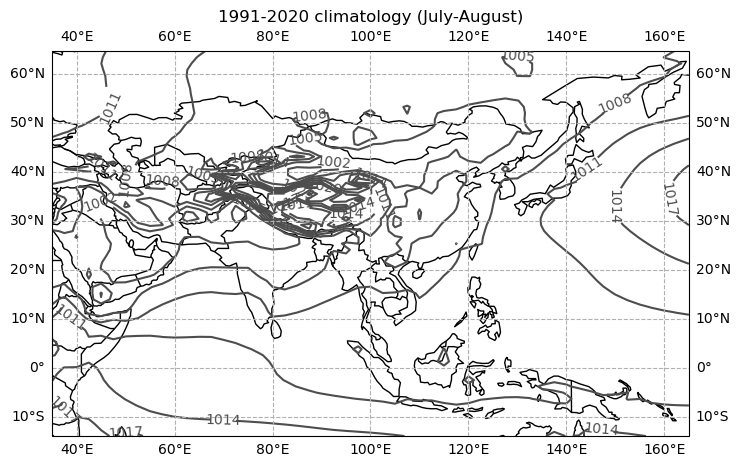

In [39]:
if 'Pass' in similarity_results:
    plot_climatology('psl')

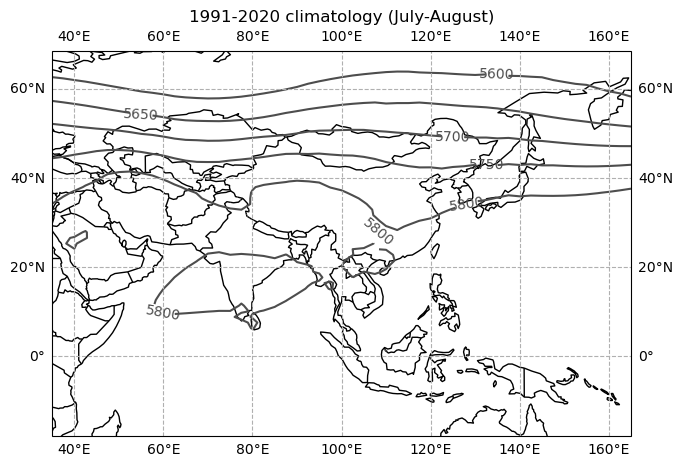

In [40]:
if 'Pass' in similarity_results:
    plot_climatology('zg500')

In [41]:
if 'Pass' in similarity_results:
    da_psl_clim = ceaa_format(clim_dict['psl'], 'psl')
    da_zg500_clim = ceaa_format(clim_dict['zg500'], 'zg500')
    ds = xr.merge([da_psl_clim, da_zg500_clim])
    ds.attrs = global_attrs
    ds.attrs['data_tier'] = 'tier3'
    step_clim = 'Calculated the 1991-2020 climatology (July-August).'
    ds.attrs['processing'] = ''f'{step_download_spatial_select} {step_clim}'
    encoding = get_encoding(ds)
    outfname = f'{outdir}/CSIRO_UNSEEN_tier3_{model}_climatology.nc'
    ds.to_netcdf(outfname, encoding=encoding)
    print(outfname)

/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data/CSIRO_UNSEEN_tier3_IPSL-CM6A-LR_climatology.nc
